In [19]:
import numpy as np
import gudhi
import tadasets

%load_ext autoreload
%autoreload 2

from persistent_laplacian_methods.dense_matrix_methods import *
from persistent_laplacian_methods.dense_boundary_matrix_helpers import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
points = tadasets.torus(
    n=500,
    c=2.0,       
    a=1.0,       
    seed=42,
)

rips = gudhi.RipsComplex(
    points=points,
    max_edge_length=0.9,
)
simplex_tree = rips.create_simplex_tree(
    max_dimension=5,
)

In [8]:
D, levels, cuts = boundary_matrices(simplex_tree)

In [24]:
i, j = 1000, 2000 
l = 2500
q = 4
print("Filtration length: ", len(cuts))
print_boundary_dimensions(D, cuts, i, j)

Filtration length:  4766
matrix             K_1000           K_2000
D_1           (500, 1000)      (500, 2000)
D_2           (1000, 862)     (2000, 3421)
D_3            (862, 463)     (3421, 3576)
D_4            (463, 186)     (3576, 2489)
D_5             (186, 56)     (2489, 1185)


In [22]:
prepare_up_persistent_relative_cochain_laplacian(D, cuts, q, i, j, l)

(array([[ 1., -1.,  0., ...,  0.,  0.,  0.],
        [ 1.,  0., -1., ...,  0.,  0.,  0.],
        [ 0.,  1., -1., ...,  0.,  0.,  0.],
        ...,
        [ 0.,  0.,  0., ...,  0.,  1.,  0.],
        [ 0.,  0.,  0., ...,  0.,  0.,  1.],
        [ 0.,  0.,  0., ...,  1., -1.,  1.]], shape=(13921, 12141)),
 11618,
 9028)

In [25]:
print_relative_coboundary_dimensions(cuts, i, j, l)

matrix          whole matrix         B (outer)         E (cross)        A (middle)
delta_0            (1500, 0)          (500, 0)          (500, 0)         (1000, 0)
delta_1         (4492, 1500)       (1933, 500)      (1933, 1000)      (2559, 1000)
delta_2         (6624, 4492)      (3511, 1933)      (3511, 2559)      (3113, 2559)
delta_3         (6170, 6624)      (3867, 3511)      (3867, 3113)      (2303, 3113)
delta_4         (3910, 6170)      (2781, 3867)      (2781, 2303)      (1129, 2303)
delta_5            (0, 3910)         (0, 2781)         (0, 1129)         (0, 1129)


In [16]:
from functools import partial
import timeit

import numpy as np
import pandas as pd

from persistent_laplacian_methods import *


REPEATS = 5
NUMBER = 1

rcond_svd = 1e-6
rcond_schur = rcond_svd**2


# q=0 has no incoming coboundary and hence no persistent-down term.
# D[q] supplies delta_{q-1} = D[q].T.
q_values = sorted(D)


def arguments_for(q):
    return prepare_up_persistent_relative_cochain_laplacian(
        D,
        cuts,
        q,
        i,
        j,
        l,
    )


rows = []


def record_timings(
    method,
    q,
    run,
    matrix_shape,
    A_shape,
    n_q_relative,
    n_qm1_relative,
    clearing_h=np.nan,
):
    samples = timeit.repeat(
        run,
        repeat=REPEATS,
        number=NUMBER,
    )

    for repeat, elapsed in enumerate(samples, start=1):
        rows.append({
            "q": q,
            "method": method,
            "repeat": repeat,
            "seconds": elapsed / NUMBER,
            "matrix_rows": matrix_shape[0],
            "matrix_cols": matrix_shape[1],
            "V_q_dim": n_q_relative,
            "V_qm1_dim": n_qm1_relative,
            "A_rows": A_shape[0],
            "A_cols": A_shape[1],
            "clearing_h": clearing_h,
        })


# Independent methods
for q in q_values:
    matrix, n_q_relative, n_qm1_relative = arguments_for(q)

    matrix_shape = matrix.shape
    A_shape = matrix[
        n_q_relative:,
        n_qm1_relative:,
    ].shape

    methods = {
        "Schur": partial(
            compute_schur_D,
            matrix,
            n_q_relative,
            n_qm1_relative,
            rcond=rcond_schur,
        ),
        "Null-space SVD": partial(
            compute_null_space_D,
            matrix,
            n_q_relative,
            n_qm1_relative,
            rcond=rcond_svd,
        ),
        "Reduced SVD": partial(
            compute_reduced_svd_D,
            matrix,
            n_q_relative,
            n_qm1_relative,
            rcond=rcond_svd,
        ),
    }

    for method, run in methods.items():
        print(f"Timing {method}, q={q}")

        record_timings(
            method=method,
            q=q,
            run=run,
            matrix_shape=matrix_shape,
            A_shape=A_shape,
            n_q_relative=n_q_relative,
            n_qm1_relative=n_qm1_relative,
        )


# Clearing SVD: cochain dimensions must be processed low to high.
#
# At degree q:
#     current constraint = A_{q-1}
#     known image       = im(A_{q-2})
#
previous_output = None
previous_A = None

for q in q_values:
    matrix, n_q_relative, n_qm1_relative = arguments_for(q)

    matrix_shape = matrix.shape
    A = matrix[
        n_q_relative:,
        n_qm1_relative:,
    ]
    A_shape = A.shape

    # Check A_{q-1} A_{q-2} = 0.
    if previous_A is not None:
        assert np.allclose(
            A @ previous_A,
            0.0,
            rtol=0.0,
            atol=1e-12,
        ), f"Relative coboundaries do not compose to zero at q={q}"

    # Rank(A_{q-2}), obtained at the preceding cohomological degree.
    clearing_h = (
        0
        if previous_output is None
        else previous_output[1]
    )

    # The parameter is still named higher_output in the existing routine,
    # although here it comes from the preceding cohomological degree.
    run = partial(
        compute_null_space_clearing_D,
        matrix,
        n_q_relative,
        n_qm1_relative,
        higher_output=previous_output,
        rcond=rcond_svd,
    )

    print(f"Timing Clearing SVD, q={q}, h={clearing_h}")

    record_timings(
        method="Clearing SVD",
        q=q,
        run=run,
        matrix_shape=matrix_shape,
        A_shape=A_shape,
        n_q_relative=n_q_relative,
        n_qm1_relative=n_qm1_relative,
        clearing_h=clearing_h,
    )

    L_clearing, current_output = run()

    L_schur_lstsq = compute_schur_D_lstsq(
        matrix,
        n_q_relative,
        n_qm1_relative,
        rcond=rcond_svd,
    )

    assert np.allclose(
        L_clearing,
        L_schur_lstsq,
        rtol=1e-8,
        atol=1e-10,
    ), (
        "Clearing disagrees with least-squares Schur "
        f"at q={q}"
    )

    previous_A = A
    previous_output = current_output


print(
    "Relative clearing agrees with least-squares Schur "
    "in every dimension."
)


timings = pd.DataFrame(rows)

summary = (
    timings
    .groupby(
        [
            "q",
            "method",
            "matrix_rows",
            "matrix_cols",
            "V_q_dim",
            "V_qm1_dim",
            "A_rows",
            "A_cols",
        ],
        as_index=False,
    )
    .agg(
        clearing_h=("clearing_h", "first"),
        median_seconds=("seconds", "median"),
        min_seconds=("seconds", "min"),
        max_seconds=("seconds", "max"),
    )
)

summary["clearing_h"] = summary["clearing_h"].astype("Int64")

display(summary)

Timing Schur, q=1
Timing Null-space SVD, q=1
Timing Reduced SVD, q=1
Timing Schur, q=2
Timing Null-space SVD, q=2
Timing Reduced SVD, q=2
Timing Schur, q=3
Timing Null-space SVD, q=3
Timing Reduced SVD, q=3
Timing Schur, q=4
Timing Null-space SVD, q=4
Timing Reduced SVD, q=4
Timing Schur, q=5
Timing Null-space SVD, q=5
Timing Reduced SVD, q=5
Timing Clearing SVD, q=1, h=0
Timing Clearing SVD, q=2, h=0
Timing Clearing SVD, q=3, h=914
Timing Clearing SVD, q=4, h=1633
Timing Clearing SVD, q=5, h=1480
Relative clearing agrees with least-squares Schur in every dimension.


,q,method,matrix_rows,matrix_cols,V_q_dim,V_qm1_dim,A_rows,A_cols,clearing_h,median_seconds,min_seconds,max_seconds
0,1,Clearing SVD,1500,0,500,0,1000,0,0,0.001167,0.001058,0.003192
1,1,Null-space SVD,1500,0,500,0,1000,0,<NA>,0.000170,0.000140,0.000240
2,1,Reduced SVD,1500,0,500,0,1000,0,<NA>,0.000134,0.000121,0.000234
3,1,Schur,1500,0,500,0,1000,0,<NA>,0.000138,0.000131,0.000383
4,2,Clearing SVD,4492,1500,1933,500,2559,1000,0,0.476893,0.476770,0.493535
5,2,Null-space SVD,4492,1500,1933,500,2559,1000,<NA>,0.494999,0.478170,0.534986
6,2,Reduced SVD,4492,1500,1933,500,2559,1000,<NA>,0.306090,0.304730,0.320188
7,2,Schur,4492,1500,1933,500,2559,1000,<NA>,1.682270,1.577032,1.831631
8,3,Clearing SVD,6624,4492,3511,1933,3113,2559,914,1.658855,1.602936,1.785899
9,3,Null-space SVD,6624,4492,3511,1933,3113,2559,<NA>,3.789557,3.684649,4.109907


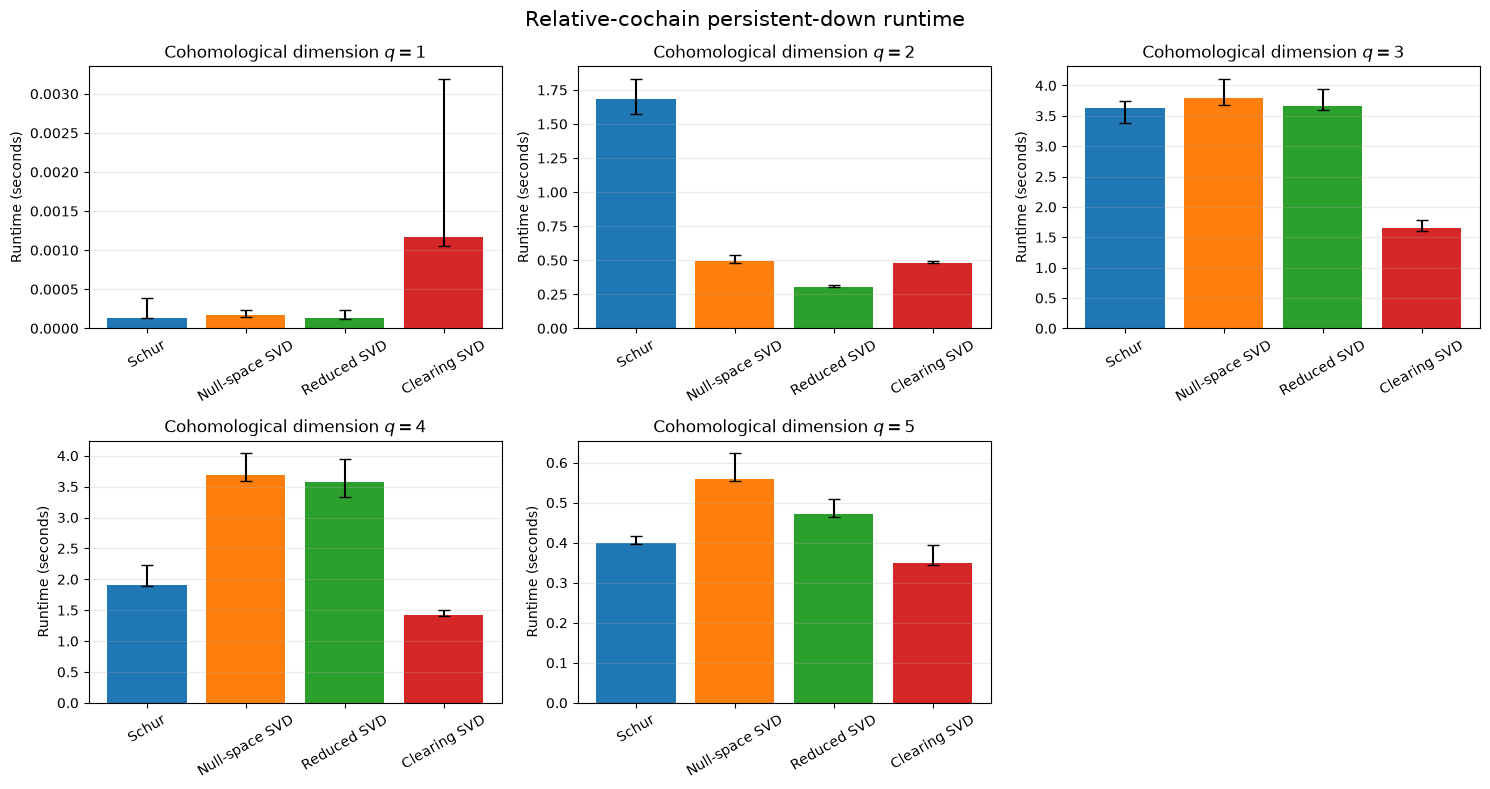

In [26]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


q_values = np.sort(summary["q"].unique())

method_order = [
    "Schur",
    "Null-space SVD",
    "Reduced SVD",
    "Clearing SVD",
]

ncols = 3
nrows = math.ceil(len(q_values) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5 * ncols, 4 * nrows),
)

axes = np.atleast_1d(axes).ravel()

colors = dict(zip(method_order, plt.cm.tab10.colors))

for ax, q in zip(axes, q_values):
    data = summary[summary["q"] == q].copy()

    data["method"] = pd.Categorical(
        data["method"],
        categories=method_order,
        ordered=True,
    )

    data = data.sort_values("method")

    median = data["median_seconds"].to_numpy()
    lower = median - data["min_seconds"].to_numpy()
    upper = data["max_seconds"].to_numpy() - median

    method_labels = data["method"].astype(str).to_list()

    ax.bar(
        method_labels,
        median,
        yerr=np.vstack([lower, upper]),
        color=[colors[method] for method in method_labels],
        capsize=4,
    )

    ax.set_title(f"Cohomological dimension $q={q}$")
    ax.set_ylabel("Runtime (seconds)")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)

# Hide unused panels.
for ax in axes[len(q_values):]:
    ax.set_visible(False)

fig.suptitle(
    "Relative-cochain persistent-down runtime",
    fontsize=15,
)

fig.tight_layout()
plt.show()